# SmishGuard SMS phishing model development

This notebook downloads/checks the public dataset, audits annotation quality,
cleans duplicate records, explores training data, compares three small classifiers,
and exports a complete pipeline for **local Django inference**. No separate model
hosting service or paid inference API is required.

The experiment predicts **smishing (1) versus non-smishing (0)**. The original
`ham` and `spam` labels are kept for slice analysis. Marketing spam is not silently
renamed phishing. The app's suspicious band is a decision-policy outcome, not a
fourth source label. No real user SMS should be added to this notebook.

Run cells top to bottom using the project ML environment. Outputs are reproducible
for the pinned versions, data checksum, fixed seed, and documented split heuristic.
Numbers below describe this benchmark, not production protection guarantees.

## Notebook route
1. Environment and source verification
2. Data dictionary and quality audit
3. Cleaning and duplicate/template handling
4. Grouped train/validation/test split
5. Training-only exploratory charts
6. Model training and validation comparison
7. Freeze model selection and decision thresholds
8. Held-out evaluation, uncertainty, and limitations
9. Export model bundles and test local inference

Each code cell has one short task. Reusable grouping, metrics, and inference code
is in `smishguard_ml/`, rather than a single large notebook cell.

## 1. Environment
Create a virtual environment and install `ml/requirements.txt` following `ml/README.md`.
Choose that environment as the notebook kernel. Installation is deliberately not
performed inside notebook cells. The tested runtime is Python 3.12.

In [1]:
from pathlib import Path
import sys, json, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             RocCurveDisplay, classification_report)
from sklearn.calibration import CalibrationDisplay
from smishguard_ml.training import (
    canonical_text, make_template_groups, grouped_split, build_candidates,
    positive_probability, binary_metrics, threshold_table, select_threshold,
    risk_bands, group_bootstrap_intervals, file_sha256, environment_versions, write_json,
)

Locate the ML folder whether Jupyter was opened from the repository root, `ml`, or `ml/scripts`.

In [3]:
ML_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'smishguard_ml').is_dir()), None)
if ML_ROOT is None and (Path.cwd() / 'ml' / 'smishguard_ml').is_dir():
    ML_ROOT = Path.cwd() / 'ml'
if ML_ROOT is None:
    raise RuntimeError('Open this notebook from the project root or ml folder.')
RAW = ML_ROOT / 'data' / 'raw'
REPORTS = ML_ROOT / 'reports'
FIGURES = REPORTS / 'figures'
ARTIFACTS = ML_ROOT / 'artifacts'
for folder in [REPORTS, FIGURES, ARTIFACTS]:
    folder.mkdir(parents=True, exist_ok=True)

Set the experiment protocol **before viewing model results**. The 95% goals are aspirations, not claims.

In [4]:
SEED = 42
GROUP_SIMILARITY = 0.90
MAX_VALIDATION_FPR = 0.05
SOURCE_URL = 'https://data.mendeley.com/datasets/f45bkkt8pr/1'
CSV_SHA256 = '649844f1c62a6b27e145eaf17a65f7010c56c390e11a794ea8329993a05ba71e'
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
display(pd.Series(environment_versions(), name='Installed version'))

python          3.12.14
numpy             2.5.4
scipy            1.18.1
scikit-learn      1.9.1
pandas            3.0.6
joblib            1.6.0
Name: Installed version, dtype: str

In [5]:
def finish_plot(filename, source='Mendeley SMS Phishing v1; current benchmark run'):
    fig = plt.gcf()
    fig.text(0.01, 0.005, source, fontsize=8)
    fig.tight_layout(rect=(0, 0.035, 1, 1))
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 2. Dataset source and data dictionary
Mishra and Soni (2022), **SMS Phishing Dataset for Machine Learning and Pattern
Recognition**, Mendeley Data v1, DOI `10.17632/f45bkkt8pr.1`, CC BY 4.0.
[Publisher page](https://data.mendeley.com/datasets/f45bkkt8pr/1).

The publisher describes 5,971 rows: 4,844 ham, 489 spam, 638 smishing.
`TEXT` is the raw message. `LABEL` is the annotation. `URL`, `EMAIL`, and `PHONE`
are publisher-supplied extracted flags. We inspect these flags but **do not train
on them**, so Django only needs raw message text and no publisher extraction scripts.
The publisher's age, collection method, annotation quality, and representativeness
limit the conclusions. Language coverage is not certified by these labels.

Use the local verified CSV. If it is missing, run the downloader; an existing valid file needs no network.

In [6]:
csv_path = RAW / 'Dataset_5971.csv'
if not csv_path.exists():
    import subprocess
    subprocess.run([sys.executable, str(ML_ROOT / 'scripts' / 'download_dataset.py')], check=True)
assert file_sha256(csv_path) == CSV_SHA256, 'Unexpected data version or file modification'
raw = pd.read_csv(csv_path, encoding='utf-8-sig')
assert {'LABEL', 'TEXT', 'URL', 'EMAIL', 'PHONE'} <= set(raw.columns)
print('Raw rows and columns:', raw.shape)
display(raw.dtypes.rename('dtype').to_frame())

Raw rows and columns: (5971, 5)


,dtype
LABEL,str
TEXT,str
URL,str
EMAIL,str
PHONE,str


Inspect label spelling and missing values without printing potentially sensitive message text or clickable links.

In [7]:
display(raw['LABEL'].value_counts(dropna=False).rename_axis('Original spelling').to_frame('Rows'))
display(raw.isna().sum().to_frame('Missing values'))
quality = {'raw_rows': len(raw), 'source_csv_sha256': CSV_SHA256,
           'rows_with_replacement_character': int(raw.TEXT.str.contains('�', regex=False).sum())}
print('Rows containing an existing Unicode replacement character:',
      quality['rows_with_replacement_character'])

,Rows
Original spelling,
ham,4844
Smishing,616
spam,466
Spam,23
smishing,22


,Missing values
LABEL,0
TEXT,0
URL,0
EMAIL,0
PHONE,0


Rows containing an existing Unicode replacement character: 145


Normalize label capitalization only; do not invent labels. Existing replacement characters indicate upstream text loss and are recorded, not silently decoded as another encoding.

In [8]:
df = raw.rename(columns={'TEXT': 'text', 'LABEL': 'source_label'}).copy()
df['source_row_id'] = np.arange(len(df))
df['source_label'] = df.source_label.astype('string').str.strip().str.casefold()
allowed_labels = {'ham', 'spam', 'smishing'}
assert set(df.source_label.dropna().unique()) <= allowed_labels, 'Unrecognized source labels'
quality['normalized_label_counts'] = {str(k): int(v) for k, v in df.source_label.value_counts().items()}
display(df.source_label.value_counts().to_frame('Raw rows after label normalization'))

,Raw rows after label normalization
source_label,
ham,4844
smishing,638
spam,489


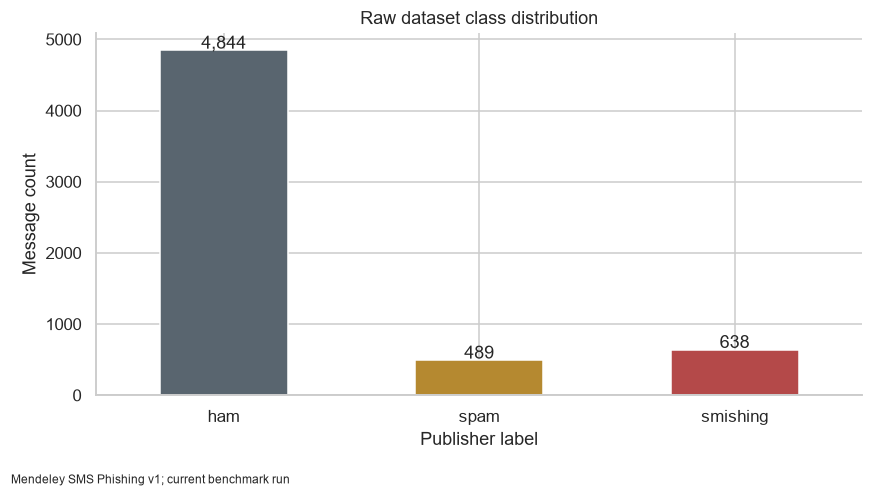

In [9]:
counts = df.source_label.value_counts().reindex(['ham', 'spam', 'smishing'])
ax = counts.plot.bar(rot=0, color=['#59656f', '#b58930', '#b44949'])
ax.set(title='Raw dataset class distribution', xlabel='Publisher label', ylabel='Message count')
for i, value in enumerate(counts):
    ax.text(i, value + 25, f'{value:,}', ha='center')
finish_plot('01_raw_class_distribution.png')

## 3. Clean records and document every exclusion
Keep raw text as the model input. Do not strip URLs, digits, punctuation, or apply
stemming: these may contain useful evidence. Canonical text below is used for
duplicate auditing only; fitted vectorizers handle model preprocessing inside
each training fold and inside the exported model.

In [10]:
valid = df.text.notna() & df.source_label.notna()
valid &= df.text.astype('string').str.strip().str.len().fillna(0) > 0
quality['invalid_or_empty_rows_removed'] = int((~valid).sum())
df = df.loc[valid].copy()
df['text'] = df.text.astype(str)
df['canonical_key'] = df.text.map(canonical_text)
quality['normalized_duplicate_rows'] = int(df.duplicated('canonical_key').sum())
print('Normalized duplicate rows:', quality['normalized_duplicate_rows'])

Normalized duplicate rows: 140


Identical normalized messages can have contradictory source annotations. Remove
**all rows** belonging to such groups rather than selecting the label that helps
accuracy. This conservative rule also removes ham-versus-spam conflicts even
though both map to non-smishing. Retain an ID-only exclusion audit, not raw text.

In [11]:
label_counts = df.groupby('canonical_key').source_label.nunique()
conflicting_keys = set(label_counts[label_counts > 1].index)
conflict_mask = df.canonical_key.isin(conflicting_keys)
quality['conflicting_text_groups'] = len(conflicting_keys)
quality['conflicting_rows_removed'] = int(conflict_mask.sum())
df.loc[conflict_mask, ['source_row_id', 'source_label']].to_csv(
    REPORTS / 'excluded_conflicting_row_ids.csv', index=False)
df = df.loc[~conflict_mask].copy()
print('Conflicting groups / rows excluded:', len(conflicting_keys), quality['conflicting_rows_removed'])

Conflicting groups / rows excluded: 34 68


In [12]:
before_deduplication = len(df)
df = df.drop_duplicates('canonical_key', keep='first').copy().reset_index(drop=True)
quality['same_label_duplicate_rows_removed'] = before_deduplication - len(df)
quality['clean_rows'] = len(df)
df['target'] = (df.source_label == 'smishing').astype(int)
assert not df.canonical_key.duplicated().any()
display(pd.Series(quality, dtype=object).to_frame('Audit finding'))
write_json(REPORTS / 'data_quality.json', quality)

,Audit finding
raw_rows,5971
source_csv_sha256,649844f1c62a6b27e145eaf17a65f7010c56c390e11a79...
rows_with_replacement_character,145
normalized_label_counts,"{'ham': 4844, 'smishing': 638, 'spam': 489}"
invalid_or_empty_rows_removed,0
normalized_duplicate_rows,140
conflicting_text_groups,34
conflicting_rows_removed,68
same_label_duplicate_rows_removed,106
clean_rows,5797


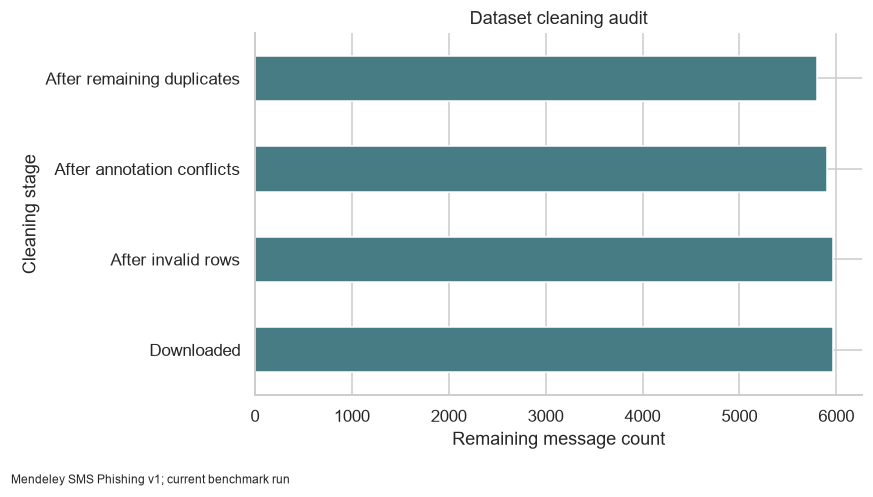

In [13]:
stages = pd.Series({'Downloaded': quality['raw_rows'],
                   'After invalid rows': quality['raw_rows'] - quality['invalid_or_empty_rows_removed'],
                   'After annotation conflicts': before_deduplication,
                   'After remaining duplicates': len(df)})
ax = stages.plot.barh(color='#487c85')
ax.set(title='Dataset cleaning audit', xlabel='Remaining message count', ylabel='Cleaning stage')
finish_plot('02_cleaning_audit.png')

## 4. Keep similar templates in one partition
Mask obvious URLs, email addresses, and digit sequences **for grouping only**,
then link high-similarity character TF-IDF templates. Connected components become
split groups. This label-free dataset-organization step uses all texts to identify
overlap, not to fit classifier features. It is a heuristic: it does not establish
complete sender, domain, temporal, or campaign independence.

The split is approximately 60% training / 20% validation / 20% test. Template groups
can shift these percentages. We never search for a random seed with better scores.

In [14]:
df['group_id'], grouping_audit = make_template_groups(df.text, GROUP_SIMILARITY)
parts = grouped_split(df, SEED)
train, validation, test = (parts[name] for name in ['train', 'validation', 'test'])
write_json(REPORTS / 'grouping_audit.json', grouping_audit)
display(pd.Series(grouping_audit).to_frame('Grouping finding'))

,Grouping finding
similarity_threshold,0.9
groups,5401
largest_group,14
method,masked-template char TF-IDF cosine connected c...


In [15]:
split_rows = []
for name, part in parts.items():
    split_rows.append({'partition': name, 'rows': len(part), 'groups': part.group_id.nunique(),
                       'smishing': int(part.target.sum()), 'non_smishing': int((part.target == 0).sum())})
split_summary = pd.DataFrame(split_rows).set_index('partition')
display(split_summary)
assignments = pd.concat([p[['source_row_id', 'source_label', 'target', 'group_id']].assign(partition=n)
                         for n, p in parts.items()], ignore_index=True)
assignments.to_csv(REPORTS / 'split_assignments.csv', index=False)
assert len(assignments) == len(df) and not assignments.source_row_id.duplicated().any()

,rows,groups,smishing,non_smishing
partition,,,,
train,3477,3240,316,3161
validation,1160,1083,106,1054
test,1160,1078,106,1054


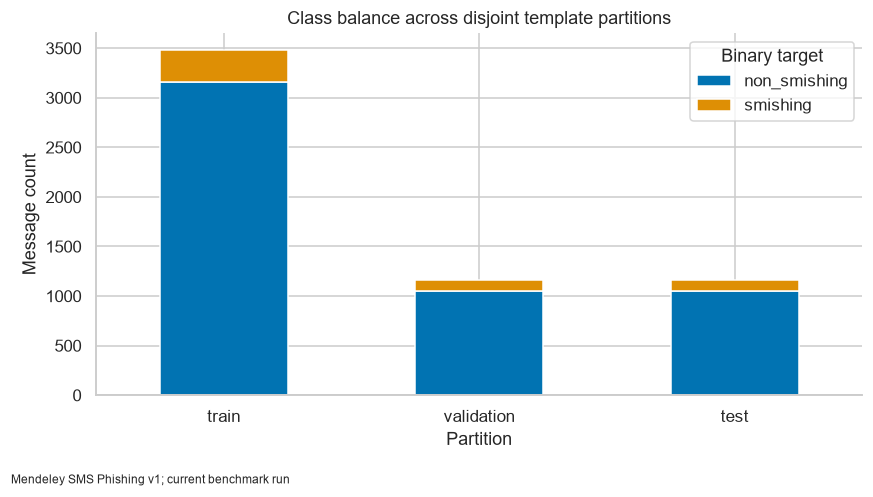

In [16]:
ax = split_summary[['non_smishing', 'smishing']].plot.bar(stacked=True, rot=0)
ax.set(title='Class balance across disjoint template partitions',
       xlabel='Partition', ylabel='Message count')
ax.legend(title='Binary target')
finish_plot('03_partition_balance.png')

## 5. Explore training data only
After splitting, detailed EDA uses training data. Test label totals above document
stratification; test message content and model outcomes are not used for feature
or threshold decisions. Public dataset examples are still treated as untrusted
text and their links are never fetched.

In [17]:
eda = train[['text', 'source_label', 'target']].copy()
eda['characters'] = eda.text.str.len()
eda['words'] = eda.text.str.split().str.len()
eda['has_link'] = eda.text.str.contains(r'https?://|www[.]', case=False, regex=True)
display(eda.groupby('source_label')[['characters', 'words']].agg(['median', 'mean', 'max']).round(1))

characters              words           
                 median   mean  max median  mean  max
source_label                                         
ham                53.0   71.2  611   11.0  14.3  125
smishing          146.0  142.6  306   23.0  23.1   51
spam              142.0  134.2  379   24.0  23.3   61

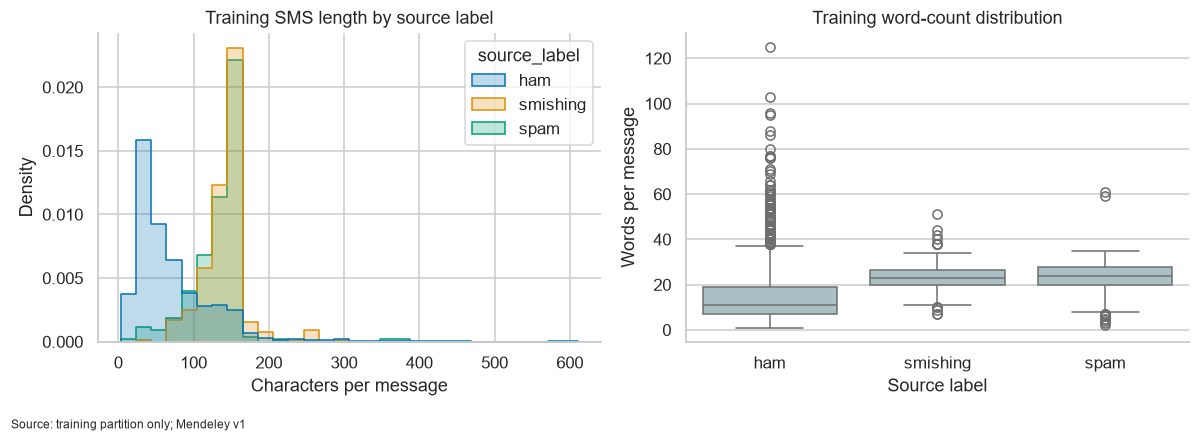

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=eda, x='characters', hue='source_label', bins=30,
             element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set(title='Training SMS length by source label', xlabel='Characters per message', ylabel='Density')
sns.boxplot(data=eda, x='source_label', y='words', ax=axes[1], color='#a6c3c8')
axes[1].set(title='Training word-count distribution', xlabel='Source label', ylabel='Words per message')
finish_plot('04_training_message_lengths.png', 'Source: training partition only; Mendeley v1')

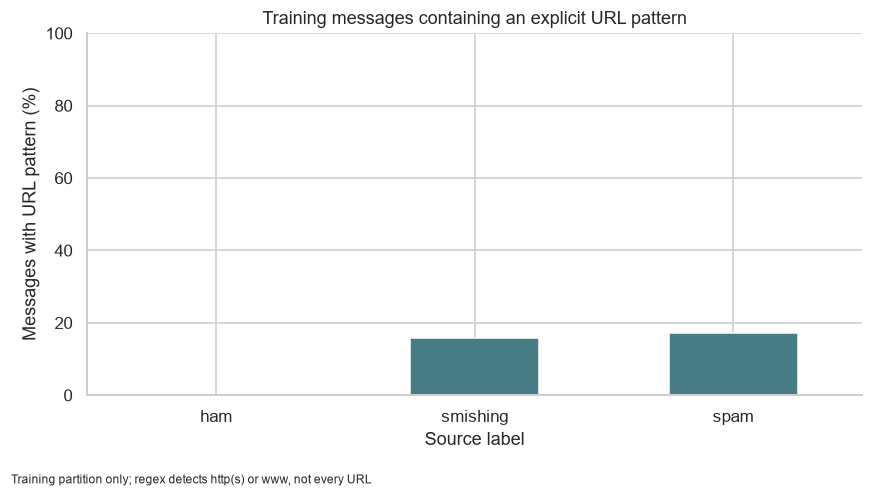

In [19]:
link_rates = eda.groupby('source_label').has_link.mean().mul(100).sort_index()
ax = link_rates.plot.bar(rot=0, color='#487c85')
ax.set(title='Training messages containing an explicit URL pattern',
       xlabel='Source label', ylabel='Messages with URL pattern (%)', ylim=(0, 100))
finish_plot('05_training_link_patterns.png', 'Training partition only; regex detects http(s) or www, not every URL')

Common words describe the training corpus. They do not prove a word is malicious or explain any individual prediction.

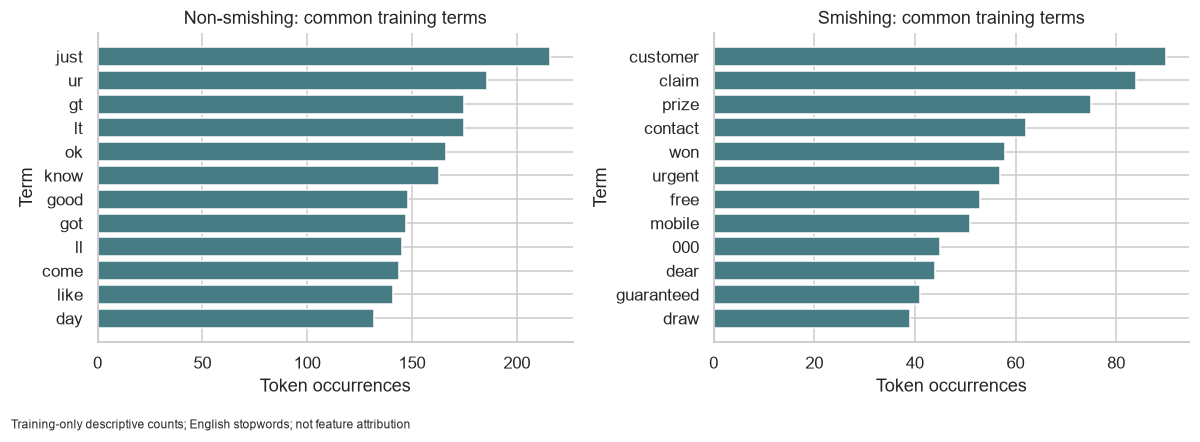

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for target, ax, title in [(0, axes[0], 'Non-smishing'), (1, axes[1], 'Smishing')]:
    counter = CountVectorizer(stop_words='english', min_df=2, max_features=5000)
    matrix = counter.fit_transform(eda.loc[eda.target == target, 'text'])
    totals = np.asarray(matrix.sum(axis=0)).ravel()
    top = np.argsort(totals)[-12:]
    ax.barh(counter.get_feature_names_out()[top], totals[top], color='#487c85')
    ax.set(title=f'{title}: common training terms', xlabel='Token occurrences', ylabel='Term')
finish_plot('06_training_common_terms.png', 'Training-only descriptive counts; English stopwords; not feature attribution')

## 6. Train three candidates and a majority baseline
Every candidate uses word (1–2 gram) and character (3–5 gram) TF-IDF features.
Vocabulary and IDF are fitted inside training folds, never on validation/test text.
Logistic Regression, Multinomial Naive Bayes, and Linear SVM are each sigmoid-
calibrated using three **group-disjoint training folds**. The test set is not used
for calibration. The selected export includes the fitted vectorizers and calibrator.

We select the model by **validation average precision**, breaking ties by F1 and
name. Average precision summarizes the precision–recall ranking and is not exactly
the trapezoidal area under a PR curve. Fixed model settings keep this experiment
small; they are not an exhaustive hyperparameter search. There is no GPU requirement.

In [21]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(np.zeros((len(train), 1)), train.target)
baseline_val_p = baseline.predict_proba(np.zeros((len(validation), 1)))[:, list(baseline.classes_).index(1)]
baseline_validation = binary_metrics(validation.target, baseline_val_p)
display(pd.Series(baseline_validation).to_frame('Majority baseline on validation'))

,Majority baseline on validation
accuracy,0.908621
precision,0.000000
recall,0.000000
f1,0.000000
false_positive_rate,0.000000
average_precision,0.091379
roc_auc,0.500000
brier_score,0.091379
tn,1054.000000
fp,0.000000


In [22]:
candidates = build_candidates(train, SEED)
fitted, validation_probabilities, training_seconds, validation_rows = {}, {}, {}, []
for name, model in candidates.items():
    started = time.perf_counter()
    model.fit(train.text.tolist(), train.target.to_numpy())
    training_seconds[name] = time.perf_counter() - started
    fitted[name] = model
    probabilities = positive_probability(model, validation.text)
    validation_probabilities[name] = probabilities
    validation_rows.append({'model': name, 'training_seconds': training_seconds[name],
                            **binary_metrics(validation.target, probabilities)})
    print(f'{name}: trained and calibrated in {training_seconds[name]:.2f} seconds')

logistic_regression: trained and calibrated in 2.76 seconds


multinomial_nb: trained and calibrated in 2.66 seconds


linear_svm: trained and calibrated in 3.88 seconds


In [23]:
validation_results = pd.DataFrame(validation_rows).set_index('model')
display(validation_results[['average_precision', 'precision', 'recall', 'f1',
                            'false_positive_rate', 'brier_score', 'training_seconds']].round(4))
validation_results.to_csv(REPORTS / 'validation_comparison.csv')

,average_precision,precision,recall,f1,false_positive_rate,brier_score,training_seconds
model,,,,,,,
logistic_regression,0.9335,0.8727,0.9057,0.8889,0.0133,0.0189,2.7647
multinomial_nb,0.9471,0.8393,0.8868,0.8624,0.0171,0.0200,2.6617
linear_svm,0.9282,0.8868,0.8868,0.8868,0.0114,0.0187,3.8825


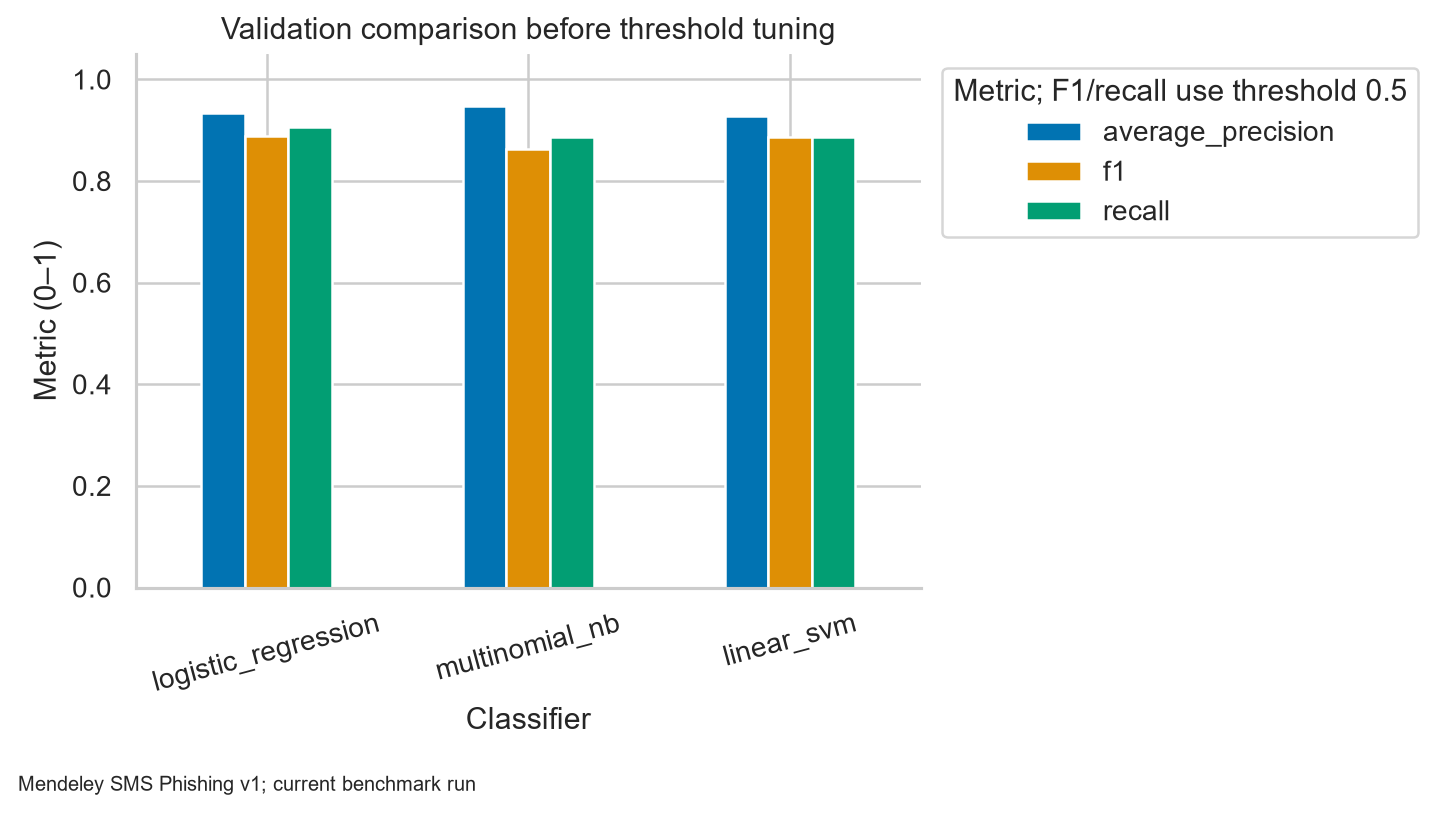

In [24]:
ax = validation_results[['average_precision', 'f1', 'recall']].plot.bar(rot=15)
ax.set(title='Validation comparison before threshold tuning', xlabel='Classifier', ylabel='Metric (0–1)', ylim=(0, 1.05))
ax.legend(title='Metric; F1/recall use threshold 0.5', loc='upper left', bbox_to_anchor=(1.01, 1))
finish_plot('07_validation_model_comparison.png')

## 7. Freeze selection and thresholds on validation data
For each candidate, examine thresholds 0.05–0.95. Choose the highest validation
recall subject to at most 5% non-smishing high-risk alerts; break ties by precision,
F1, and the higher threshold. This ceiling is a validation constraint, **not a
guarantee on unseen data**. Report recall even when it misses the 95% aspiration.

The lower suspicious-band threshold is the predeclared heuristic `min(0.20, upper/2)`.
It is not a separately learned ground-truth class. We report its extra benign alerts.

In [25]:
winner_name = validation_results.reset_index().sort_values(
    ['average_precision', 'f1', 'model'], ascending=[False, False, True]).iloc[0]['model']
thresholds, threshold_curves = {}, {}
for name, probabilities in validation_probabilities.items():
    curve = threshold_table(validation.target, probabilities)
    upper = select_threshold(curve, MAX_VALIDATION_FPR)
    thresholds[name] = {'lower': min(0.20, upper / 2), 'upper': upper}
    threshold_curves[name] = curve
    curve.to_csv(REPORTS / f'validation_thresholds_{name}.csv', index=False)
print('Selected on validation only:', winner_name)
display(pd.DataFrame(thresholds).T.rename_axis('model'))

Selected on validation only: multinomial_nb


,lower,upper
model,,
logistic_regression,0.045,0.09
multinomial_nb,0.075,0.15
linear_svm,0.065,0.13


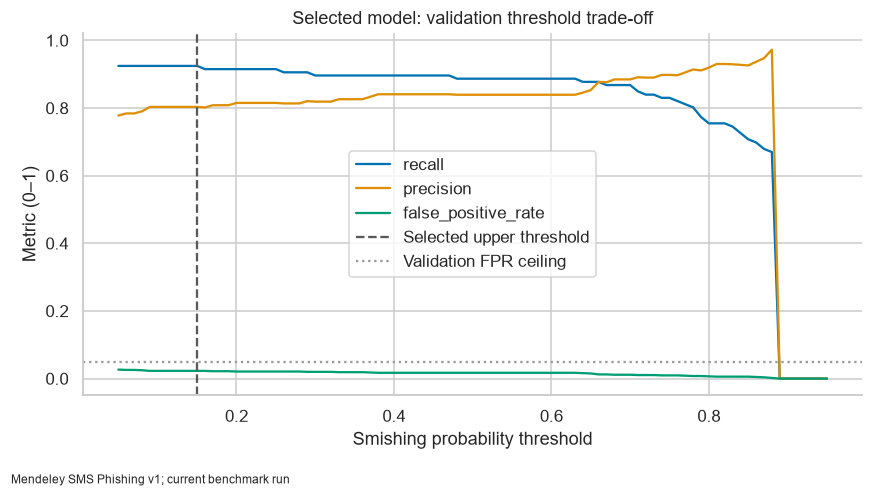

In [26]:
curve = threshold_curves[winner_name]
fig, ax = plt.subplots()
for metric in ['recall', 'precision', 'false_positive_rate']:
    ax.plot(curve.threshold, curve[metric], label=metric)
ax.axvline(thresholds[winner_name]['upper'], color='#595959', linestyle='--', label='Selected upper threshold')
ax.axhline(MAX_VALIDATION_FPR, color='#999999', linestyle=':', label='Validation FPR ceiling')
ax.set(title='Selected model: validation threshold trade-off', xlabel='Smishing probability threshold', ylabel='Metric (0–1)')
ax.legend(loc='best')
finish_plot('08_validation_threshold_tradeoff.png')

In [27]:
protocol = {'seed': SEED, 'dataset_sha256': CSV_SHA256, 'grouping': grouping_audit,
            'selection_metric': 'validation average_precision; ties F1, name',
            'winner': winner_name, 'thresholds': thresholds,
            'max_validation_fpr': MAX_VALIDATION_FPR,
            'split_counts': split_summary.reset_index().to_dict(orient='records'),
            'environment': environment_versions(),
            'fit_scope': 'training only; group-aware internal calibration; no post-test refit'}
write_json(REPORTS / 'frozen_protocol.json', protocol)
print('Selection and thresholds frozen before held-out predictions.')

Selection and thresholds frozen before held-out predictions.


## 8. Held-out test evaluation
All candidates now receive the same untouched test partition for comparison.
**Do not switch the winner or retune thresholds after inspecting these results.**
This experiment exports the already fitted training-only model so its evaluated
thresholds remain consistent. A later refit requires a new version and evaluation.

In [28]:
test_probabilities, test_rows = {}, []
for name, model in fitted.items():
    p = positive_probability(model, test.text)
    test_probabilities[name] = p
    test_rows.append({'model': name, 'upper_threshold': thresholds[name]['upper'],
                     **binary_metrics(test.target, p, thresholds[name]['upper'])})
baseline_test_p = baseline.predict_proba(np.zeros((len(test), 1)))[:, list(baseline.classes_).index(1)]
test_rows.append({'model': 'majority_baseline', 'upper_threshold': 0.5,
                  **binary_metrics(test.target, baseline_test_p)})
test_results = pd.DataFrame(test_rows).set_index('model')
display(test_results.round(4))
test_results.to_csv(REPORTS / 'heldout_test_comparison.csv')

,upper_threshold,accuracy,precision,recall,f1,false_positive_rate,average_precision,roc_auc,brier_score,tn,fp,fn,tp
model,,,,,,,,,,,,,
logistic_regression,0.09,0.9560,0.6846,0.9623,0.8000,0.0446,0.9482,0.9937,0.0185,1007,47,4,102
multinomial_nb,0.15,0.9612,0.7402,0.8868,0.8069,0.0313,0.9025,0.9860,0.0306,1021,33,12,94
linear_svm,0.13,0.9647,0.7372,0.9528,0.8313,0.0342,0.9332,0.9910,0.0171,1018,36,5,101
majority_baseline,0.50,0.9086,0.0000,0.0000,0.0000,0.0000,0.0914,0.5000,0.0914,1054,0,106,0


In [29]:
winner = fitted[winner_name]
test_p = test_probabilities[winner_name]
lower, upper = thresholds[winner_name]['lower'], thresholds[winner_name]['upper']
test_pred = (test_p >= upper).astype(int)
print(classification_report(test.target, test_pred,
      target_names=['non_smishing', 'smishing'], zero_division=0))
selected_metrics = binary_metrics(test.target, test_p, upper)
write_json(REPORTS / 'selected_test_metrics.json', selected_metrics)

              precision    recall  f1-score   support

non_smishing       0.99      0.97      0.98      1054
    smishing       0.74      0.89      0.81       106

    accuracy                           0.96      1160
   macro avg       0.86      0.93      0.89      1160
weighted avg       0.97      0.96      0.96      1160



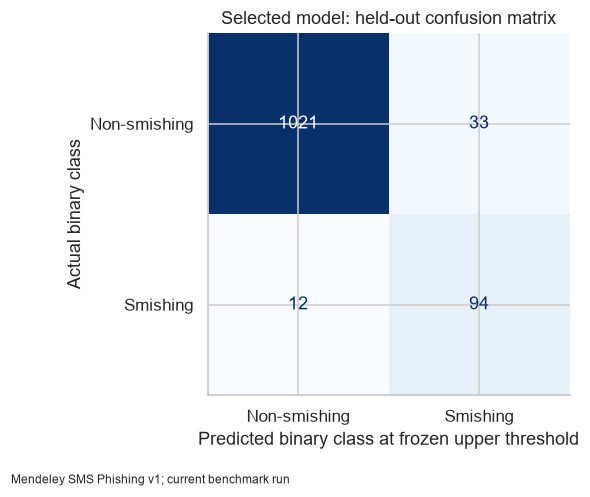

In [30]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ConfusionMatrixDisplay.from_predictions(test.target, test_pred,
    display_labels=['Non-smishing', 'Smishing'], colorbar=False, cmap='Blues', ax=ax)
ax.set(title='Selected model: held-out confusion matrix',
       xlabel='Predicted binary class at frozen upper threshold', ylabel='Actual binary class')
finish_plot('09_test_confusion_matrix.png')

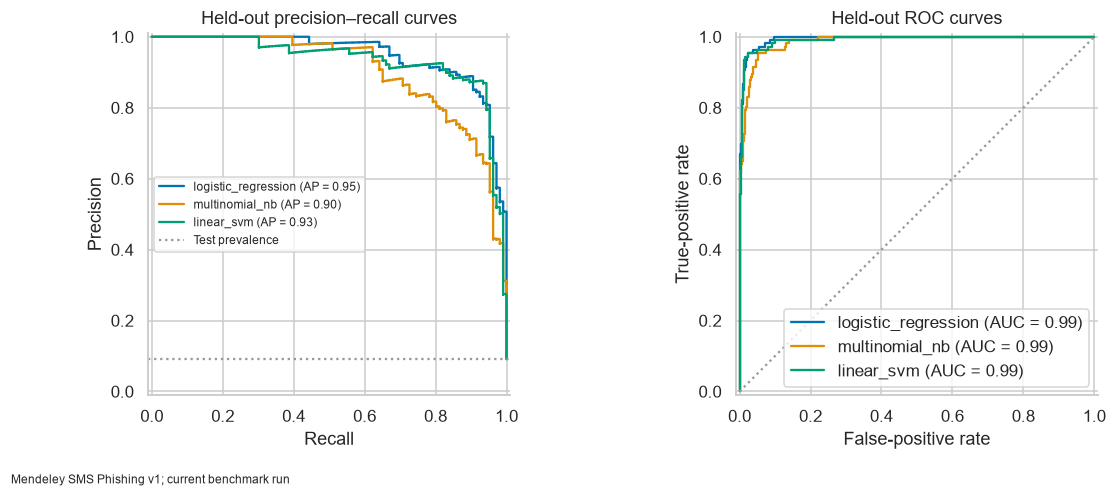

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(test.target, p, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(test.target, p, name=name, ax=axes[1])
axes[0].axhline(test.target.mean(), color='#999999', linestyle=':', label='Test prevalence')
axes[0].set(title='Held-out precision–recall curves', xlabel='Recall', ylabel='Precision')
axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], color='#999999', linestyle=':')
axes[1].set(title='Held-out ROC curves', xlabel='False-positive rate', ylabel='True-positive rate')
finish_plot('10_test_pr_and_roc.png')

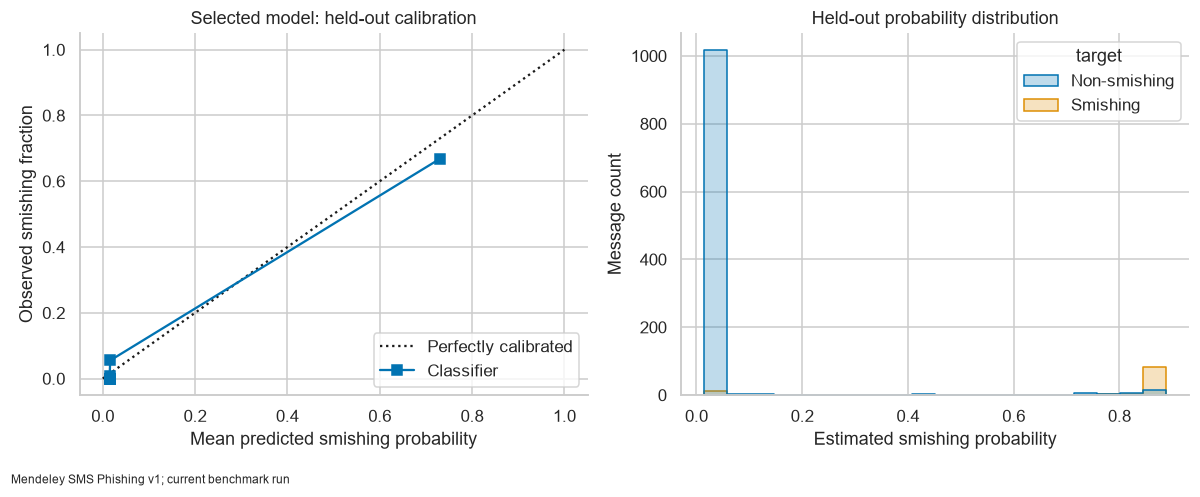

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
CalibrationDisplay.from_predictions(test.target, test_p, n_bins=8, strategy='quantile', ax=axes[0])
axes[0].set(title='Selected model: held-out calibration',
            xlabel='Mean predicted smishing probability', ylabel='Observed smishing fraction')
sns.histplot(x=test_p, hue=test.target.map({0: 'Non-smishing', 1: 'Smishing'}),
             bins=20, element='step', ax=axes[1])
axes[1].set(title='Held-out probability distribution', xlabel='Estimated smishing probability', ylabel='Message count')
finish_plot('11_test_calibration_and_scores.png')

Report each original source-label slice; promotional spam is a useful false-positive stress test.

In [33]:
test_detail = test[['source_row_id', 'source_label', 'target', 'group_id']].copy()
test_detail['probability'] = test_p
test_detail['high_risk_prediction'] = test_pred
test_detail['risk_band'] = risk_bands(test_p, lower, upper)
slice_summary = test_detail.groupby('source_label').agg(
    messages=('target', 'size'), high_risk_rate=('high_risk_prediction', 'mean'))
display(slice_summary)
test_detail.to_csv(REPORTS / 'test_predictions_metadata.csv', index=False)
slice_summary.to_csv(REPORTS / 'test_source_label_slices.csv')

,messages,high_risk_rate
source_label,,
ham,962,0.001040
smishing,106,0.886792
spam,92,0.347826


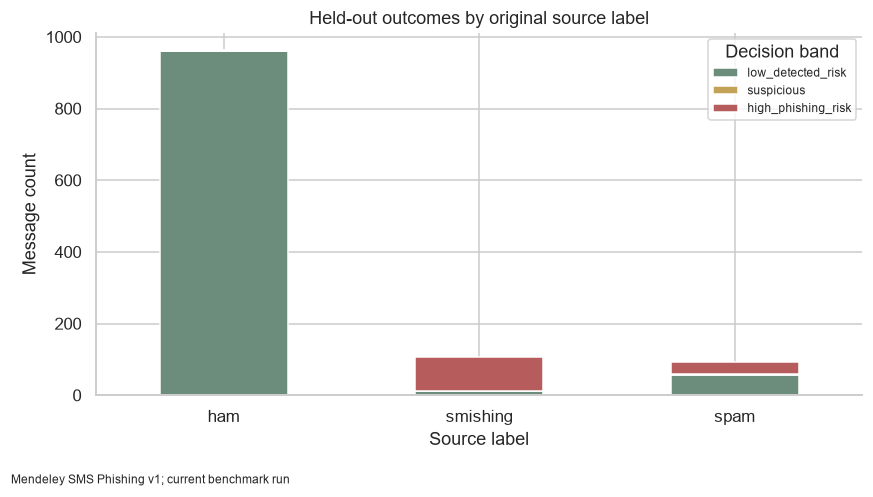

In [34]:
bands = pd.crosstab(test_detail.source_label, test_detail.risk_band).reindex(
    columns=['low_detected_risk', 'suspicious', 'high_phishing_risk'], fill_value=0)
ax = bands.plot.bar(stacked=True, rot=0, color=['#6c8d7b', '#c3a256', '#b65c5c'])
ax.set(title='Held-out outcomes by original source label', xlabel='Source label', ylabel='Message count')
ax.legend(title='Decision band', fontsize=8)
finish_plot('12_test_risk_bands.png')

In [35]:
alert = test_p >= lower
benign = test.target.to_numpy() == 0
band_metrics = {
    'high_risk_recall': selected_metrics['recall'],
    'alert_recall_including_suspicious': float(alert[~benign].mean()),
    'benign_alert_rate_including_suspicious': float(alert[benign].mean()),
    'suspicious_referral_rate': float((test_detail.risk_band == 'suspicious').mean()),
    'non_suspicious_coverage': float((test_detail.risk_band != 'suspicious').mean()),
}
display(pd.Series(band_metrics).to_frame('Held-out rate'))
write_json(REPORTS / 'risk_band_metrics.json', band_metrics)

,Held-out rate
high_risk_recall,0.886792
alert_recall_including_suspicious,0.896226
benign_alert_rate_including_suspicious,0.034156
suspicious_referral_rate,0.003448
non_suspicious_coverage,0.996552


Approximate 95% percentile intervals resample template groups. They quantify benchmark sampling uncertainty, not deployment reliability.

In [36]:
intervals = group_bootstrap_intervals(test, test_p, upper, SEED, repeats=400)
display(intervals.round(4))
intervals.to_csv(REPORTS / 'group_bootstrap_intervals.csv', index=False)

,metric,lower_95,upper_95
0,precision,0.6019,0.8292
1,recall,0.7891,0.9501
2,f1,0.7018,0.8739
3,false_positive_rate,0.0190,0.0461
4,average_precision,0.8050,0.9559


Measure warm single-message inference locally. This excludes Android, network time, cold loading, and Django request handling.

In [37]:
latencies_ms = []
for text in test.text.iloc[:100]:
    start = time.perf_counter()
    winner.predict_proba([text])
    latencies_ms.append((time.perf_counter() - start) * 1000)
latency = {'samples': len(latencies_ms), 'median_ms': float(np.median(latencies_ms)),
           'p95_ms': float(np.percentile(latencies_ms, 95)), 'scope': 'warm model only on development CPU'}
display(pd.Series(latency).to_frame('Inference timing'))
write_json(REPORTS / 'inference_latency.json', latency)

,Inference timing
samples,100
median_ms,2.57975
p95_ms,4.57192
scope,warm model only on development CPU


In [38]:
targets = pd.DataFrame([
    {'target': 'Accuracy >= 95%', 'observed': selected_metrics['accuracy'], 'met': selected_metrics['accuracy'] >= .95},
    {'target': 'High-risk recall >= 95%', 'observed': selected_metrics['recall'], 'met': selected_metrics['recall'] >= .95},
    {'target': 'High-risk FPR <= 5%', 'observed': selected_metrics['false_positive_rate'],
     'met': selected_metrics['false_positive_rate'] <= .05},
])
display(targets)
targets.to_csv(REPORTS / 'provisional_target_checks.csv', index=False)

,target,observed,met
0,Accuracy >= 95%,0.961207,True
1,High-risk recall >= 95%,0.886792,False
2,High-risk FPR <= 5%,0.031309,True


### Interpretation limits
The source is small, old, imbalanced, and has annotation conflicts. Removed duplicates
make our row counts differ from papers using the uncleaned source. Template grouping
reduces one source of leakage but does not prove independence of all scam campaigns.
There is no prospective phone-user study, guaranteed Arabic/Urdu coverage, or evidence
that a percentage is a probability of financial loss. Use a separate recent,
language-appropriate external dataset before making broader performance claims.

Do not silently optimize against the test results. If changing the protocol after
review, label this run exploratory and obtain a new independent evaluation set.

## 9. Export fitted models for the backend
The models are created/exported here at the end of the experiment. Each bundle has
a complete fitted vectorizer/classifier/calibrator, frozen thresholds, version,
data fingerprint, dependency versions, and evaluation metadata. `selected/` contains
the winner selected on **validation** data; test metrics do not change that selection.

Only scikit-learn built-ins are serialized: no notebook-defined preprocessing
function is needed at inference time. Keep these trusted bundles with Django on
the customer's machine/server. Training data and Jupyter are not backend dependencies.

In [39]:
from datetime import datetime, timezone
from importlib.metadata import version
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
export_paths = {}
for name, model in fitted.items():
    folder = ARTIFACTS / run_id / name
    folder.mkdir(parents=True, exist_ok=True)
    joblib.dump(model, folder / 'model.joblib', compress=3)
    export_paths[name] = folder
print('Export directory:', ARTIFACTS / run_id)

Export directory: C:\Users\DONI BUTT\Documents\Capstone orject for client\ml\artifacts\20261022T113407Z


In [40]:
for name, folder in export_paths.items():
    metadata = {
        'schema_version': 1, 'model_version': f'smishguard-{name}-{run_id}',
        'algorithm': name, 'environment': environment_versions(), 'dataset': SOURCE_URL,
        'dataset_sha256': CSV_SHA256, 'model_sha256': file_sha256(folder / 'model.joblib'),
        'label_mapping': {'0': 'non_smishing', '1': 'smishing'}, 'maximum_input_characters': 5000,
        'decision_policy': {'version': 'validation-fpr-v1', 'lower_threshold': thresholds[name]['lower'],
                            'upper_threshold': thresholds[name]['upper']},
        'validation': validation_results.loc[name].to_dict(), 'heldout_test': test_results.loc[name].to_dict(),
        'fit_scope': protocol['fit_scope'], 'coverage': 'English-oriented historical benchmark only',
        'selection_winner': name == winner_name,
    }
    write_json(folder / 'metadata.json', metadata)

In [41]:
import shutil
selected_directory = ARTIFACTS / 'selected'
selected_directory.mkdir(exist_ok=True)
for filename in ['model.joblib', 'metadata.json']:
    shutil.copy2(export_paths[winner_name] / filename, selected_directory / filename)
inference_pins = chr(10).join(f'{p}=={version(p)}' for p in ['numpy', 'scipy', 'scikit-learn', 'joblib']) + chr(10)
(selected_directory / 'requirements-inference.txt').write_text(inference_pins, encoding='utf-8')
write_json(REPORTS / 'latest_run.json', {'run_id': run_id, 'selected_algorithm': winner_name,
                                       'bundle': str(selected_directory.relative_to(ML_ROOT))})
print('Django-ready selected bundle:', selected_directory)

Django-ready selected bundle: C:\Users\DONI BUTT\Documents\Capstone orject for client\ml\artifacts\selected


Check the local inference wrapper. These are synthetic smoke-test inputs, not an evaluation dataset.

In [42]:
from smishguard_ml.inference import SmishGuardPredictor
predictor = SmishGuardPredictor(selected_directory)
synthetic_examples = [
    'Are we still meeting at the library after class?',
    'URGENT: Your account is suspended. Verify your password at https://example.invalid/verify',
]
display(pd.DataFrame([predictor.predict(text) for text in synthetic_examples]))
assert predictor.predict('1234')['status'] == 'unsupported_or_insufficient_text'
for invalid in ['', '   ', None, 'x' * 5001]:
    try:
        predictor.predict(invalid)
        raise AssertionError('Invalid input was accepted')
    except ValueError:
        pass

,status,verdict,model_estimate,model_version,policy_version,observed_indicators,indicator_note,language_coverage,mode,safety_guarantee
0,completed,low_detected_risk,0.014917,smishguard-multinomial_nb-20261022T113407Z,validation-fpr-v1,[],Observed patterns are not proof or model-attri...,English-oriented benchmark; language is not au...,local_backend_model,False
1,completed,high_phishing_risk,0.888028,smishguard-multinomial_nb-20261022T113407Z,validation-fpr-v1,"[contains_link, urgency_language, credential_o...",Observed patterns are not proof or model-attri...,English-oriented benchmark; language is not au...,local_backend_model,False


The held-out classifier metrics above cover the estimator on all test records.
Measure the deployed wrapper's extra abstentions separately so its input guard
cannot silently turn unassessed text into a safe prediction.

In [43]:
guarded_outputs = [predictor.predict(text) for text in test.text]
guard_completed = np.array([r['status'] == 'completed' for r in guarded_outputs])
wrapper_audit = {'test_messages': len(test), 'completed': int(guard_completed.sum()),
                 'abstained': int((~guard_completed).sum()),
                 'smishing_abstained': int(((~guard_completed) & (test.target.to_numpy() == 1)).sum()),
                 'coverage': float(guard_completed.mean()),
                 'guard': 'coarse Latin-script and letter-count check; not language detection'}
display(pd.Series(wrapper_audit).to_frame('Deployed wrapper on held-out data'))
write_json(REPORTS / 'inference_wrapper_coverage.json', wrapper_audit)

,Deployed wrapper on held-out data
test_messages,1160
completed,1157
abstained,3
smishing_abstained,0
coverage,0.997414
guard,coarse Latin-script and letter-count check; no...


Reload in a fresh Python process to catch accidental dependence on notebook variables or custom pickled classes.

In [44]:
import subprocess
check_text = 'Please confirm our study session at the library tomorrow.'
expected = predictor.predict(check_text)
snippet = ('import json,sys; from smishguard_ml.inference import SmishGuardPredictor; '
           'print(json.dumps(SmishGuardPredictor(sys.argv[1]).predict(sys.argv[2])))')
result = subprocess.run([sys.executable, '-c', snippet, str(selected_directory), check_text],
                        cwd=ML_ROOT, capture_output=True, text=True, check=True)
assert json.loads(result.stdout) == expected
print('Fresh-process reload and prediction parity passed.')

Fresh-process reload and prediction parity passed.


### Django integration
Install the inference dependencies pinned in `artifacts/selected/requirements-inference.txt`
and the `smishguard_ml` package (`pip install ./ml` from the project root). Include the
trusted selected bundle in the customer's backend distribution, outside public media
and static directories. Load `SmishGuardPredictor(bundle_path)` once per worker and
call `.predict(message_text)` from the authenticated, validated DRF analysis endpoint.

The model loads and predicts locally in the Django process. No separate model server,
paid API, or PostgreSQL storage of model binaries is needed. If the mobile app talks
to Django on another machine, it still needs that machine's reachable API; a local
backend model is not automatically an on-device/offline mobile model.

The wrapper includes only a coarse script/length guard, not a language detector.
It can reject mostly non-Latin text but cannot certify that Latin-script text is
English. Observed rule indicators are not verified model explanations. Never load
untrusted joblib files: checksum verification detects accidental changes, not a
malicious replacement of both metadata and model. See `BACKEND_INTEGRATION.md`.

### Files to use for the report
Use `reports/data_quality.json`, `split_assignments.csv`, validation/test comparison
CSVs, group-bootstrap intervals, target checks, and saved figures. These are actual
results of this run. `artifacts/selected/metadata.json` identifies the evaluated model.
Do not paste only accuracy into the report; discuss smishing recall, false alarms,
the suspicious referral band, class imbalance, and source limitations.

In [45]:
summary = {
    'selected_algorithm': winner_name, 'clean_rows': len(df),
    'test_rows': len(test), 'test_metrics': selected_metrics,
    'risk_band_metrics': band_metrics, 'latency': latency,
    'figure_count': len(list(FIGURES.glob('*.png'))),
    'artifact_path': str(selected_directory.relative_to(ML_ROOT)),
}
write_json(REPORTS / 'run_summary.json', summary)
print(json.dumps(summary, indent=2))

{
  "selected_algorithm": "multinomial_nb",
  "clean_rows": 5797,
  "test_rows": 1160,
  "test_metrics": {
    "accuracy": 0.9612068965517241,
    "precision": 0.7401574803149606,
    "recall": 0.8867924528301887,
    "f1": 0.8068669527896996,
    "false_positive_rate": 0.031309297912713474,
    "average_precision": 0.9024811980135006,
    "roc_auc": 0.985965414772117,
    "brier_score": 0.03055634383571044,
    "tn": 1021,
    "fp": 33,
    "fn": 12,
    "tp": 94
  },
  "risk_band_metrics": {
    "high_risk_recall": 0.8867924528301887,
    "alert_recall_including_suspicious": 0.8962264150943396,
    "benign_alert_rate_including_suspicious": 0.03415559772296015,
    "suspicious_referral_rate": 0.0034482758620689655,
    "non_suspicious_coverage": 0.996551724137931
  },
  "latency": {
    "samples": 100,
    "median_ms": 2.5797499692998827,
    "p95_ms": 4.571920004673301,
    "scope": "warm model only on development CPU"
  },
  "figure_count": 12,
  "artifact_path": "artifacts\\selecte